#### Evaluation

Using the saved test predictions from notebooks 04 and 05 (no training here).
- errors by hour, day type, demand level and season
- Diebold-Mariano tests
- link between errors and the patterns from notebook 03
- regional vs household

For each model the squared error is averaged over the 3 seeds first, so RMSE here = sqrt(mean over hours of the seed-mean squared error).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# scipy.stats = statistics functions (p-values, Spearman correlation)
from scipy import stats

In [2]:
# why: all seven models are checked the same way, on the same test hours
MODELS = ["naive", "rf", "xgb", "lstm", "gru", "cnn_lstm", "attention"]
DEEP = ["lstm", "gru", "cnn_lstm", "attention"]
HORIZONS = [1, 24, 168]
DATASETS = ["pjme", "uci"]

##### Load predictions

In [3]:
# load_errors: reads the saved test predictions of every model for one dataset and horizon
# and gives back the squared error of every test hour.
# why: all later steps (errors by period, significance tests) start from these hourly errors
def load_errors(name, h):
    sq = {}
    for m in MODELS:
        p = pd.read_parquet(f"../results/predictions/{name}_{m}_h{h}.parquet")
        # the prediction columns are called seed_0, seed_1, seed_2
        seeds = [c for c in p.columns if c.startswith("seed_")]
        # prediction - actual for each seed, squared, then the mean of the 3 seeds for each hour.
        # e.g. actual 100, predictions 90, 110, 105 -> errors 100, 100, 25 -> mean 75
        sq[m] = ((p[seeds].sub(p["actual"], axis=0)) ** 2).mean(axis=1)
        actual = p["actual"]
    df = pd.DataFrame(sq)
    df["actual"] = actual
    return df


# one error table for every (dataset, horizon), kept in a dictionary
errors = {(name, h): load_errors(name, h) for name in DATASETS for h in HORIZONS}
errors[("pjme", 24)].head()

,naive,rf,xgb,lstm,gru,cnn_lstm,attention,actual
Datetime,,,,,,,,
2016-02-06 08:00:00,946729.0,4.313516e+05,1.666962e+05,4.819445e+06,2.057007e+06,5.794060e+06,9.224631e+05,32668.0
2016-02-06 09:00:00,483025.0,1.268886e+05,4.449858e+04,3.736053e+06,1.785064e+06,5.009407e+06,1.358267e+06,33474.0
2016-02-06 10:00:00,399424.0,7.295841e+04,2.114355e+05,8.908763e+05,2.140002e+05,1.627487e+06,1.591502e+05,32987.0
2016-02-06 11:00:00,364816.0,2.906887e+05,4.817081e+05,9.352091e+04,1.414487e+05,2.472759e+05,2.914433e+05,32173.0
2016-02-06 12:00:00,237169.0,1.146184e+06,2.115069e+06,3.356340e+05,5.868885e+05,8.434764e+04,8.236462e+05,31337.0


##### Labels for each test hour

Peak / low thresholds = top / bottom 10% of the train load (same as notebook 03).

In [4]:
# season: changes a month number into a season name, e.g. 7 -> summer
def season(month):
    return {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
            6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}[month]


# why: every test hour gets labels (hour, day type, demand level, season),
# so the error can be reported for each group and not only as one average
labels = {}
for name in DATASETS:
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    test = pd.read_parquet(f"../data/processed/{name}_test.parquet")
    # peak / low limits come from the train part: top 10% and bottom 10% of the load
    hi, lo = train["load"].quantile(0.9), train["load"].quantile(0.1)

    lab = pd.DataFrame(index=test.index)
    lab["hour"] = test["hour"]
    # day type: holiday first, then weekend, else weekday
    lab["day_type"] = np.where(test["holiday"] == 1, "holiday", np.where(test["weekend"] == 1, "weekend", "weekday"))
    # level: peak if the load is above the top limit, low if below the bottom limit, else normal
    lab["level"] = np.where(test["load"] >= hi, "peak", np.where(test["load"] <= lo, "low", "normal"))
    lab["season"] = test["month"].map(season)
    labels[name] = lab

    print(name, "peak / low threshold:", round(hi, 3), round(lo, 3))
    # value_counts() = how many hours are in each group
    print(lab["level"].value_counts().to_dict(), lab["day_type"].value_counts().to_dict(), lab["season"].value_counts().to_dict())

pjme peak / low threshold: 40850.7 24389.0
{'normal': 16998, 'low': 2912, 'peak': 1899} {'weekday': 15025, 'weekend': 6160, 'holiday': 624} {'spring': 6624, 'summer': 5929, 'winter': 4888, 'autumn': 4368}
uci peak / low threshold: 2.388 0.261
{'normal': 4866, 'peak': 230, 'low': 93} {'weekday': 3598, 'weekend': 1399, 'holiday': 192} {'summer': 2208, 'autumn': 2086, 'spring': 895}


UCI test only covers Apr-Nov 2010, so there is no winter and only 230 peak hours (UCI peaks are winter evenings in train).


##### Overall RMSE (check, should match notebooks 04 / 05)

In [5]:
# RMSE = square root of the mean squared error. .T turns the table so the models are the columns
overall = pd.DataFrame({(name, h): np.sqrt(errors[(name, h)][MODELS].mean()) for name in DATASETS for h in HORIZONS}).T
overall.index.names = ["dataset", "horizon"]
overall.round(3)

naive        rf       xgb      lstm       gru  cnn_lstm  \
dataset horizon                                                               
pjme    1        4732.501   531.655   548.692  1125.179   829.133  1067.915   
        24       4732.501  2488.012  2511.654  2580.871  2509.029  2606.918   
        168      4732.501  3816.555  3779.739  3747.489  3748.734  3740.187   
uci     1           0.791     0.462     0.457     0.491     0.493     0.508   
        24          0.791     0.574     0.562     0.593     0.591     0.601   
        168         0.791     0.589     0.578     0.599     0.598     0.599   

                 attention  
dataset horizon             
pjme    1         1150.266  
        24        2671.515  
        168       3802.535  
uci     1            0.514  
        24           0.607  
        168          0.613

Same as notebooks 04 / 05 (tiny differences for the deep models because here the seed errors are averaged before the square root).


##### Errors by period

In [6]:
# rmse_by: RMSE of every model for each group of one label,
# e.g. col = "hour" gives 24 rows, one for each hour of the day
def rmse_by(name, h, col):
    # join() puts the label next to the errors (matched by time stamp)
    df = errors[(name, h)].join(labels[name][col])
    # mean squared error in each group, then the square root
    return np.sqrt(df.groupby(col)[MODELS].mean())


# why: this table answers the research question about when the models fail (peak hours, holidays, seasons)
rows = []
for name in DATASETS:
    for h in HORIZONS:
        for col in ["hour", "day_type", "level", "season"]:
            t = rmse_by(name, h, col)
            # iterrows() goes through the table one row at a time
            for group, r in t.iterrows():
                for m in MODELS:
                    rows.append({"dataset": name, "horizon": h, "by": col, "group": group, "model": m, "rmse": r[m]})

by_period = pd.DataFrame(rows)
# saved for the dashboard and the paper
by_period.to_csv("../results/error_by_period.csv", index=False)

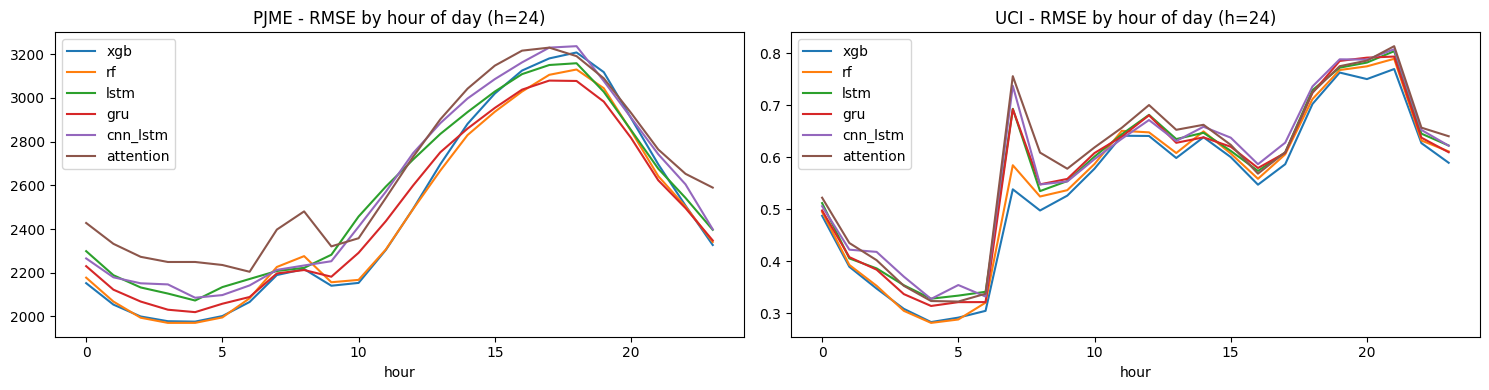

In [7]:
# RMSE by hour of day, 24h ahead
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, name in zip(ax, DATASETS):
    t = rmse_by(name, 24, "hour")
    t[["xgb", "rf"] + DEEP].plot(ax=a)
    a.set_title(name.upper() + " - RMSE by hour of day (h=24)")
plt.tight_layout()
plt.show()

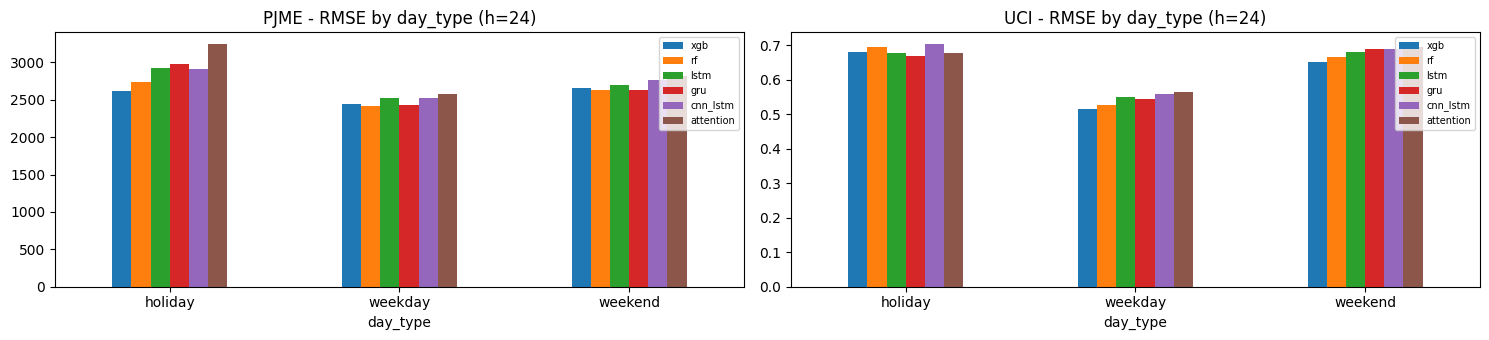

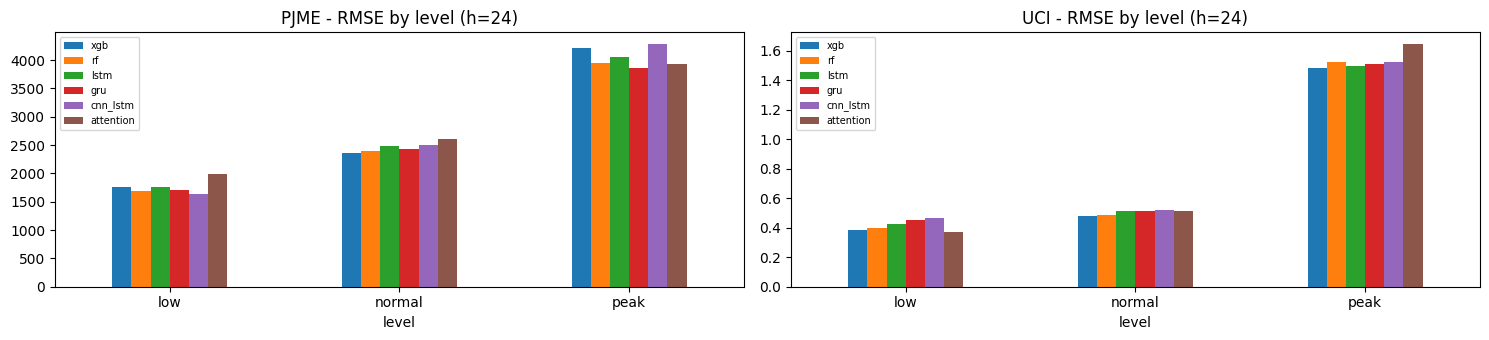

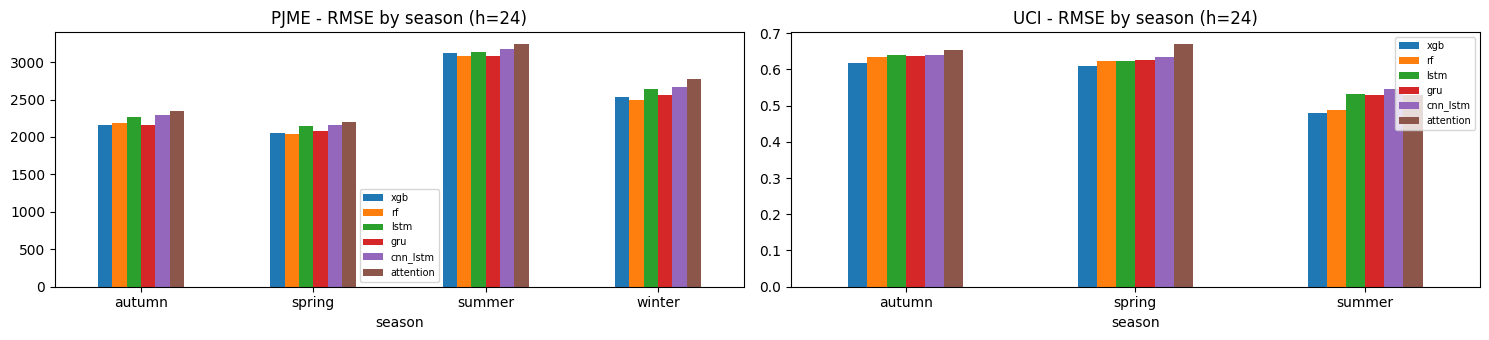

In [8]:
for col in ["day_type", "level", "season"]:
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
    for a, name in zip(ax, DATASETS):
        t = rmse_by(name, 24, col)[["xgb", "rf"] + DEEP]
        # rot=0 keeps the labels under the bars horizontal
        t.plot(kind="bar", ax=a, rot=0)
        a.set_title(f"{name.upper()} - RMSE by {col} (h=24)")
        a.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

Notes (h=24):
- PJME error is highest at 18h (evening peak) and lowest at 4h. UCI highest at 21h, lowest at 4h - same hours as the load peaks / lows in notebook 03.
- Holidays are the hardest day type for PJME. XGBoost handles them best (2618 MW vs 2447 on weekdays), the deep models
  lose more (GRU 2982 vs 2433 on weekdays), even though all models now get the holiday flag of the target hour.
  Holidays are only ~3% of the training hours, so they are hard to learn for the neural networks.
- Weekends are harder than weekdays for both datasets.
- PJME summer is the hardest season (~3100 MW vs ~2050-2350 in spring / autumn), matching the summer peak demand.
  GRU is best in summer and autumn, RF in spring and winter.
- UCI summer has the lowest error - load is low in summer (holidays away from home). XGBoost is best in every UCI season.


In [9]:
# peak vs normal vs low, all horizons
# keep only the rows for demand level and three models
t = by_period[(by_period["by"] == "level") & (by_period["model"].isin(["xgb", "gru", "lstm"]))]
# pivot_table: one row per dataset / horizon / model, one column per level
t.pivot_table(index=["dataset", "horizon", "model"], columns="group", values="rmse").round(3)

group                       low    normal      peak
dataset horizon model                              
pjme    1       gru     590.886   831.155  1084.530
                lstm    769.646  1115.887  1576.536
                xgb     480.876   517.928   837.763
        24      gru    1709.301  2432.395  3854.595
                lstm   1754.117  2487.983  4046.132
                xgb    1758.196  2360.943  4220.774
        168     gru    2448.775  3508.390  6482.249
                lstm   2624.932  3486.420  6474.368
                xgb    2785.181  3465.551  6683.901
uci     1       gru       0.270     0.428     1.258
                lstm      0.299     0.425     1.253
                xgb       0.280     0.392     1.194
        24      gru       0.453     0.510     1.510
                lstm      0.426     0.515     1.499
                xgb       0.386     0.480     1.480
        168     gru       0.445     0.516     1.534
                lstm      0.452     0.520     1.520
                xgb       0.428     0.496     1.502

In [10]:
# how much worse is the error in peak hours than in normal hours (ratio), h=24
ratio = []
for name in DATASETS:
    t = rmse_by(name, 24, "level")
    # peak RMSE divided by normal RMSE, e.g. 1.8 = the error is 1.8 times bigger in peak hours
    ratio.append((t.loc["peak"] / t.loc["normal"]).rename(name))
pd.DataFrame(ratio)[MODELS].round(2)

,naive,rf,xgb,lstm,gru,cnn_lstm,attention
pjme,1.79,1.65,1.79,1.63,1.58,1.71,1.51
uci,2.34,3.12,3.09,2.91,2.96,2.93,3.20


Peak hours are much harder: ~1.5-1.8x the normal-hour RMSE for PJME and ~2.9-3.2x for UCI, for all models.
For PJME the deep models are better in the peak hours at the longer horizons: at 24h GRU 3855 MW vs XGBoost 4221 MW,
at 168h CNN-LSTM 6227 MW vs XGBoost 6684 MW. XGBoost is better in the normal hours, which are most of the test set,
so overall they end up close. For UCI XGBoost is best in the peak hours at 1h and 24h.


##### Diebold-Mariano tests

Loss = squared error. d = loss(model A) - loss(model B). Negative statistic = model A is better.
Variance uses autocovariances up to lag h-1 and the Harvey et al. (1997) small sample correction, t-distribution with n-1 df.

In [11]:
# dm_test: Diebold-Mariano test. checks if two models really have different errors,
# or if the difference could be just luck.
# loss_a, loss_b = squared errors of model A and B for every hour, h = horizon.
# gives back the test statistic and the p-value (p < 0.05 = real difference).
# why: a lower RMSE alone is not enough to say that one model is better
def dm_test(loss_a, loss_b, h):
    # d = difference of the two losses in every hour. negative mean = model A has smaller errors
    d = (loss_a - loss_b).values
    n = len(d)
    d_mean = d.mean()
    dc = d - d_mean
    # errors of hours next to each other are linked, so the variance uses the autocovariances up to lag h - 1
    gamma = [np.sum(dc[k:] * dc[:n - k]) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:   # can happen with many lags, fall back to lag 0
        var = gamma[0] / n
    dm = d_mean / np.sqrt(var)
    # small sample correction (Harvey, Leybourne and Newbold)
    hln = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    stat = dm * hln
    # two sided p-value from the t distribution. sf() = chance of a value bigger than stat
    p = 2 * stats.t.sf(abs(stat), df=n - 1)
    return stat, p

In [12]:
# pairs to test: every model against XGBoost, and the GRU against the other deep models
pairs = [(m, "xgb") for m in ["naive", "rf"] + DEEP] + [("gru", m) for m in ["lstm", "cnn_lstm", "attention"]]

rows = []
for name in DATASETS:
    for h in HORIZONS:
        e = errors[(name, h)]
        for a, b in pairs:
            stat, p = dm_test(e[a], e[b], h)
            rows.append({"dataset": name, "horizon": h, "model_a": a, "model_b": b,
                         "dm_stat": stat, "p_value": p,
                         # better = the model with the smaller error. significant = True if p is below 0.05
                         "better": a if stat < 0 else b, "significant": p < 0.05})

dm = pd.DataFrame(rows)
dm.to_csv("../results/dm_tests.csv", index=False)
dm.round(4)

,dataset,horizon,model_a,model_b,dm_stat,p_value,better,significant
0,pjme,1,naive,xgb,76.0679,0.0000,xgb,True
1,pjme,1,rf,xgb,-6.8827,0.0000,rf,True
2,pjme,1,lstm,xgb,78.5656,0.0000,xgb,True
3,pjme,1,gru,xgb,60.5434,0.0000,xgb,True
4,pjme,1,cnn_lstm,xgb,78.4429,0.0000,xgb,True
5,pjme,1,attention,xgb,71.1571,0.0000,xgb,True
6,pjme,1,gru,lstm,-66.7841,0.0000,gru,True
7,pjme,1,gru,cnn_lstm,-58.0333,0.0000,gru,True
8,pjme,1,gru,attention,-44.6676,0.0000,gru,True
9,pjme,24,naive,xgb,11.3735,0.0000,xgb,True


In [13]:
# short view: is the better model significantly better?
# show the name of the better model only when the difference is significant
dm["result"] = np.where(dm["significant"], dm["better"], "no sig. diff")
dm.pivot_table(index=["model_a", "model_b"], columns=["dataset", "horizon"], values="result", aggfunc="first")

dataset             pjme                                       uci  \
horizon              1             24            168           1     
model_a   model_b                                                    
attention xgb        xgb           xgb  no sig. diff           xgb   
cnn_lstm  xgb        xgb           xgb  no sig. diff           xgb   
gru       attention  gru           gru  no sig. diff           gru   
          cnn_lstm   gru           gru  no sig. diff           gru   
          lstm       gru           gru  no sig. diff  no sig. diff   
          xgb        xgb  no sig. diff  no sig. diff           xgb   
lstm      xgb        xgb           xgb  no sig. diff           xgb   
naive     xgb        xgb           xgb           xgb           xgb   
rf        xgb         rf  no sig. diff  no sig. diff           xgb   

dataset                                          
horizon                       24            168  
model_a   model_b                                
attention xgb                 xgb           xgb  
cnn_lstm  xgb                 xgb           xgb  
gru       attention           gru           gru  
          cnn_lstm            gru  no sig. diff  
          lstm       no sig. diff  no sig. diff  
          xgb                 xgb           xgb  
lstm      xgb                 xgb           xgb  
naive     xgb                 xgb           xgb  
rf        xgb                 xgb           xgb

Notes:
- PJME 1h: RF and XGBoost are significantly better than all deep models (RF is also significantly better than XGBoost).
- PJME 24h: GRU, RF and XGBoost are not significantly different (GRU vs XGBoost p = 0.93). LSTM, CNN-LSTM and attention
  are significantly worse than XGBoost.
- PJME 168h: no significant difference between XGBoost, RF and any deep model (all p > 0.29). The deep models have a ~1%
  lower RMSE, but this is not significant, so they are comparable, not better.
- UCI: XGBoost is significantly better than every other model at every horizon.
- GRU is significantly better than the other deep models at PJME 1h / 24h. At 168h the deep models are not significantly different.
- The test sets are large (21,809 and 5,189 hours), so even small differences come out significant.
- For h=1 no autocorrelation lags are used (standard DM), but the errors are autocorrelated, so the p-values at 1h are probably too small.
  The 1h differences are very large anyway.


##### Errors vs temporal patterns (notebook 03)

Is the error higher in the hours where the load itself is high or more variable?
Spearman correlation between RMSE by hour (test) and the mean / std of load by hour (train).

In [14]:
# why: links the errors to the patterns of notebook 03.
# if the error by hour follows the load variability by hour, the patterns explain where the models fail
rows = []
for name in DATASETS:
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    # mean and std of the train load for each hour of the day (24 values each)
    mean_by_hour = train.groupby("hour")["load"].mean()
    std_by_hour = train.groupby("hour")["load"].std()
    for h in HORIZONS:
        t = rmse_by(name, h, "hour")
        for m in ["xgb", "gru"]:
            rows.append({"dataset": name, "horizon": h, "model": m,
                         # spearmanr = rank correlation, from -1 to 1. close to 1 = both go up and down together. [0] takes the correlation
                         "corr_mean_load": stats.spearmanr(t[m], mean_by_hour)[0],
                         "corr_std_load": stats.spearmanr(t[m], std_by_hour)[0]})
pd.DataFrame(rows).round(2)

,dataset,horizon,model,corr_mean_load,corr_std_load
0,pjme,1,xgb,0.79,0.73
1,pjme,1,gru,0.69,0.65
2,pjme,24,xgb,0.95,0.97
3,pjme,24,gru,0.95,0.98
4,pjme,168,xgb,0.94,0.97
5,pjme,168,gru,0.92,0.96
6,uci,1,xgb,0.85,0.90
7,uci,1,gru,0.87,0.87
8,uci,24,xgb,0.76,0.91
9,uci,24,gru,0.83,0.93


Errors follow the load pattern: the RMSE by hour has a high correlation with the load variability by hour from the train
data (0.91-0.98 at 24h and 168h, both datasets). So the hours that are hardest to predict are the hours where the load changes most,
which are the evening peaks found in notebook 03. At 1h the link is weaker for PJME (0.65-0.73).


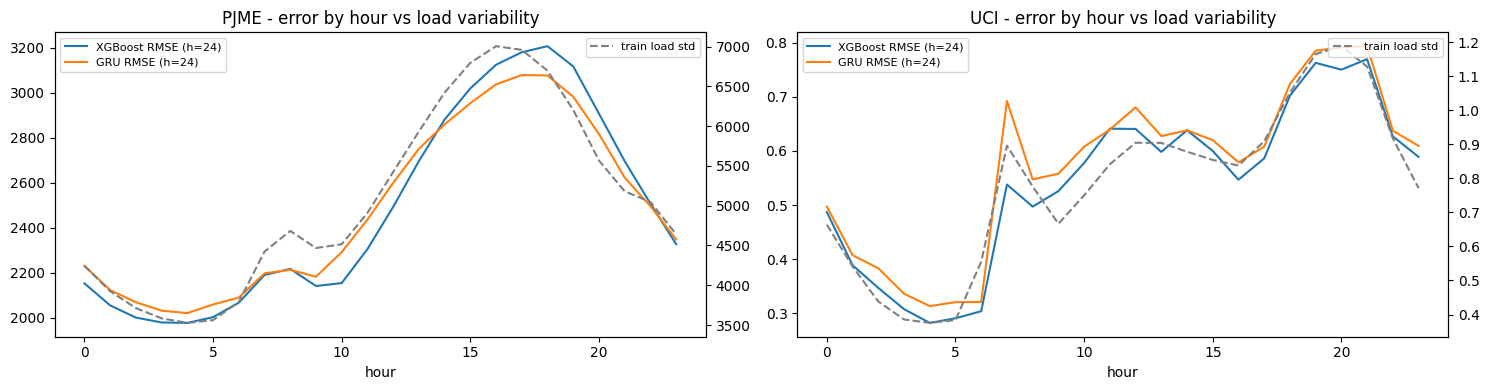

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, name in zip(ax, DATASETS):
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    t = rmse_by(name, 24, "hour")
    a.plot(t.index, t["xgb"], label="XGBoost RMSE (h=24)")
    a.plot(t.index, t["gru"], label="GRU RMSE (h=24)")
    # twinx() adds a second y axis on the right, because RMSE and std have different sizes
    a2 = a.twinx()
    a2.plot(train.groupby("hour")["load"].std(), color="grey", ls="--", label="train load std")
    a.set_title(name.upper() + " - error by hour vs load variability")
    a.set_xlabel("hour")
    a.legend(loc="upper left", fontsize=8)
    a2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

##### Regional vs household

nRMSE = RMSE / mean test load, so both datasets are on the same scale.

In [16]:
# why: MW and kW can't be compared directly, so the RMSE is divided by the mean load.
# this is used to compare the regional and the household dataset
rows = []
for name in DATASETS:
    for h in HORIZONS:
        e = errors[(name, h)]
        mean_load = e["actual"].mean()
        for m in MODELS:
            # nrmse = RMSE / mean load, e.g. 0.08 = the error is about 8% of the average load
            rows.append({"dataset": name, "horizon": h, "model": m, "nrmse": np.sqrt(e[m].mean()) / mean_load})
nrmse = pd.DataFrame(rows)
nrmse.pivot_table(index="model", columns=["dataset", "horizon"], values="nrmse").loc[MODELS].round(3)

dataset     pjme                  uci              
horizon      1      24     168    1      24     168
model                                              
naive      0.152  0.152  0.152  0.821  0.821  0.821
rf         0.017  0.080  0.123  0.480  0.596  0.612
xgb        0.018  0.081  0.122  0.475  0.583  0.600
lstm       0.036  0.083  0.120  0.510  0.616  0.622
gru        0.027  0.081  0.121  0.512  0.614  0.621
cnn_lstm   0.034  0.084  0.120  0.527  0.624  0.622
attention  0.037  0.086  0.122  0.534  0.630  0.637

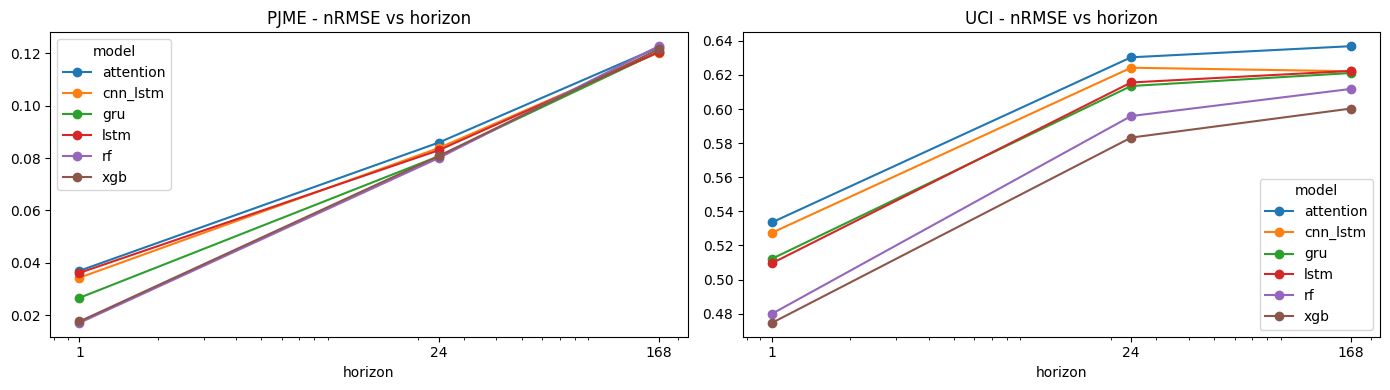

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
for a, name in zip(ax, DATASETS):
    t = nrmse[(nrmse["dataset"] == name) & (nrmse["model"] != "naive")]
    # pivot: one line per model, horizon on the x axis
    t.pivot(index="horizon", columns="model", values="nrmse").plot(ax=a, marker="o")
    # log scale on the x axis so 1, 24 and 168 are spread out
    a.set_xscale("log")
    a.set_xticks(HORIZONS)
    a.set_xticklabels(HORIZONS)
    a.set_title(name.upper() + " - nRMSE vs horizon")
plt.tight_layout()
plt.show()

In [18]:
# error growth from 1h to 24h and 168h (ratio to 1h)
g = nrmse.pivot_table(index=["dataset", "model"], columns="horizon", values="nrmse")
# divide every horizon by the 1h value, e.g. 6.9 = the error is 6.9 times bigger than at 1 hour
(g.div(g[1], axis=0)).round(2)

horizon            1     24    168
dataset model                     
pjme    attention  1.0  2.32  3.31
        cnn_lstm   1.0  2.44  3.50
        gru        1.0  3.03  4.52
        lstm       1.0  2.29  3.33
        naive      1.0  1.00  1.00
        rf         1.0  4.68  7.18
        xgb        1.0  4.58  6.89
uci     attention  1.0  1.18  1.19
        cnn_lstm   1.0  1.18  1.18
        gru        1.0  1.20  1.21
        lstm       1.0  1.21  1.22
        naive      1.0  1.00  1.00
        rf         1.0  1.24  1.27
        xgb        1.0  1.23  1.26

Notes:
- Household error is much larger than regional: nRMSE ~0.48-0.64 for UCI vs ~0.02-0.12 for PJME.
- But the two behave very differently with the horizon. PJME error grows a lot (XGBoost 1h -> 168h is ~7x), UCI only ~1.2-1.3x.
  For PJME the last few hours are very informative (ACF at lag 1 = 0.97), for UCI they are not (ACF lag 1 = 0.72, lag 24 = 0.43),
  so even the 1h forecast is already close to the long horizon error.
- The deep models lose less with the horizon than the trees (PJME LSTM ~3.3x vs XGBoost ~6.9x). They are much worse at 1h,
  but at 168h they reach the same level as the trees.
